In [3]:
import pandas as pd
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
df = pd.read_csv(url)
df['Year'] = pd.to_datetime(df['Date']).dt.year   # add Year column for Stage 4 charts
print("df loaded:", df.shape)
print(df.columns.tolist())

df loaded: (90, 19)
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class', 'Year']


In [4]:
print(df.columns.tolist())
print(df.shape)

['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class', 'Year']
(90, 19)


In [5]:
data = response.json()

records = []
for launch in data:
    record = {
        'FlightNumber': launch.get('flight_number'),
        'Date': launch.get('date_utc'),
        'BoosterVersion': launch.get('rocket'),
        'PayloadMass': None,
        'Orbit': None,
        'LaunchSite': launch.get('launchpad'),
        'Outcome': None,
        'Flights': None,
        'GridFins': None,
        'Reused': None,
        'Legs': None,
        'LandingPad': None,
        'Block': None,
        'ReusedCount': None,
        'Serial': None,
    }

    # payloads is a list of IDs (strings) in this dataset
    if launch.get('payloads'):
        p = launch['payloads'][0]
        if isinstance(p, dict):
            record['PayloadMass'] = p.get('mass_kg')
            record['Orbit'] = p.get('orbit')

    # cores is a list of IDs (strings) too
    if launch.get('cores'):
        c = launch['cores'][0]
        if isinstance(c, dict):
            record['Outcome'] = c.get('landing_success')
            record['Flights'] = c.get('flight')
            record['GridFins'] = c.get('gridfins')
            record['Reused'] = c.get('reused')
            record['Legs'] = c.get('legs')
            record['LandingPad'] = c.get('landpad')
            record['Block'] = c.get('block')
            record['ReusedCount'] = c.get('reuse_count')
            record['Serial'] = c.get('core')

    records.append(record)

df = pd.DataFrame(records)
print("Shape:", df.shape)
print(df.head())
print(df.dtypes)

Shape: (107, 15)
   FlightNumber                      Date            BoosterVersion  \
0             1  2006-03-24T22:30:00.000Z  5e9d0d95eda69955f709d1eb   
1             2  2007-03-21T01:10:00.000Z  5e9d0d95eda69955f709d1eb   
2             3  2008-08-03T03:34:00.000Z  5e9d0d95eda69955f709d1eb   
3             4  2008-09-28T23:15:00.000Z  5e9d0d95eda69955f709d1eb   
4             5  2009-07-13T03:35:00.000Z  5e9d0d95eda69955f709d1eb   

  PayloadMass Orbit                LaunchSite Outcome  Flights  GridFins  \
0        None  None  5e9e4502f5090995de566f86    None        1     False   
1        None  None  5e9e4502f5090995de566f86    None        1     False   
2        None  None  5e9e4502f5090995de566f86    None        1     False   
3        None  None  5e9e4502f5090995de566f86    None        1     False   
4        None  None  5e9e4502f5090995de566f86    None        1     False   

   Reused   Legs LandingPad Block ReusedCount                    Serial  
0   False  False       No

In [6]:
df.to_csv('dataset_part_1.csv', index=False)
print("Saved dataset_part_1.csv")
print("Rows:", len(df))

Saved dataset_part_1.csv
Rows: 107


In [7]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

static_url = "https://en.wikipedia.org/w/index.php?title=List_of_Falcon_9_and_Falcon_Heavy_launches&oldid=1027686922"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36"
}

response = requests.get(static_url, headers=headers)
print("Status code:", response.status_code)
print("Response length:", len(response.content))

soup = BeautifulSoup(response.content, "html.parser")
print("Page title:", soup.title.string if soup.title else "None")
print("Tables found:", len(soup.find_all("table")))

Status code: 200
Response length: 3293414
Page title: List of Falcon 9 and Falcon Heavy launches - Wikipedia
Tables found: 29


In [8]:
# The launch records are in the big wikitables.
# Find the table that contains 'Flight No.' in its header
launch_table = None
for table in soup.find_all("table"):
    headers_text = [th.get_text(strip=True) for th in table.find_all("th")]
    if any("Flight No." in h or "Flight No" in h for h in headers_text):
        launch_table = table
        print("Found launch table. Headers:", headers_text[:10])
        break

if launch_table is None:
    print("Launch table NOT found. Printing all table header samples:")
    for i, table in enumerate(soup.find_all("table")):
        headers_text = [th.get_text(strip=True) for th in table.find_all("th")]
        print(i, headers_text[:6])

Found launch table. Headers: ['Flight No.', 'Date andtime (UTC)', 'Version,Booster[b]', 'Launch site', 'Payload[c]', 'Payload mass', 'Orbit', 'Customer', 'Launchoutcome', 'Boosterlanding']


In [9]:
# Parse the launch records table into a DataFrame
rows = []
for tr in launch_table.find_all("tr"):
    cells = tr.find_all(["td", "th"])
    if len(cells) < 10:
        continue
    row = [c.get_text(strip=True) for c in cells]
    rows.append(row)

# First row is headers, rest is data
wiki_df = pd.DataFrame(rows[1:], columns=rows[0])
print("Shape:", wiki_df.shape)
print("Columns:", wiki_df.columns.tolist())
print(wiki_df.head())

Shape: (7, 10)
Columns: ['Flight No.', 'Date andtime (UTC)', 'Version,Booster[b]', 'Launch site', 'Payload[c]', 'Payload mass', 'Orbit', 'Customer', 'Launchoutcome', 'Boosterlanding']
  Flight No.         Date andtime (UTC)    Version,Booster[b]   Launch site  \
0          1          4 June 2010,18:45  F9 v1.0[7]B0003.1[8]  CCAFS,SLC-40   
1          2  8 December 2010,15:43[13]  F9 v1.0[7]B0004.1[8]  CCAFS,SLC-40   
2          3      22 May 2012,07:44[17]  F9 v1.0[7]B0005.1[8]  CCAFS,SLC-40   
3          4   8 October 2012,00:35[21]  F9 v1.0[7]B0006.1[8]  CCAFS,SLC-40   
4          5         1 March 2013,15:10  F9 v1.0[7]B0007.1[8]  CCAFS,SLC-40   

                               Payload[c]         Payload mass     Orbit  \
0    Dragon Spacecraft Qualification Unit                            LEO   
1       Dragondemo flight C1(Dragon C101)                       LEO(ISS)   
2  Dragondemo flight C2+[18](Dragon C102)  525kg (1,157lb)[19]  LEO(ISS)   
3           SpaceX CRS-1[22](Dragon C

In [10]:
# pandas.read_html handles rowspans/colspans automatically
tables = pd.read_html(response.text)
print("Number of tables pandas found:", len(tables))

# Find the table with the launch records (look for 'Flight No.' column)
launch_df = None
for i, t in enumerate(tables):
    if 'Flight No.' in t.columns:
        launch_df = t
        print("Found launch table at index:", i)
        print("Shape:", launch_df.shape)
        break

if launch_df is None:
    # print all table columns so we can find it
    for i, t in enumerate(tables):
        print(i, t.columns.tolist()[:5])

print(launch_df.head())

/tmp/ipykernel_645/1862637862.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


Number of tables pandas found: 29
Found launch table at index: 2
Shape: (15, 10)
   Flight No.                                Date and time (UTC)  \
0           1                                 4 June 2010, 18:45   
1           1  First flight of Falcon 9 v1.0.[11] Used a boil...   
2           2                         8 December 2010, 15:43[13]   
3           2  Maiden flight of Dragon capsule, consisting of...   
4           3                             22 May 2012, 07:44[17]   

                                Version, Booster [b]  \
0                              F9 v1.0[7] B0003.1[8]   
1  First flight of Falcon 9 v1.0.[11] Used a boil...   
2                              F9 v1.0[7] B0004.1[8]   
3  Maiden flight of Dragon capsule, consisting of...   
4                              F9 v1.0[7] B0005.1[8]   

                                         Launch site  \
0                                      CCAFS, SLC-40   
1  First flight of Falcon 9 v1.0.[11] Used a boil...   
2    

In [11]:
import io

# Re-read with StringIO to avoid the warning
tables = pd.read_html(io.StringIO(response.text))
launch_df = tables[2]  # the one with 'Flight No.'

# Every OTHER row is a footnote row. Keep only real data rows.
# Real data rows have a numeric Flight No.
launch_df = launch_df[launch_df['Flight No.'].astype(str).str.isnumeric()].reset_index(drop=True)

print("Shape after cleaning:", launch_df.shape)
print(launch_df.head(10))

Shape after cleaning: (15, 10)
   Flight No.                                Date and time (UTC)  \
0           1                                 4 June 2010, 18:45   
1           1  First flight of Falcon 9 v1.0.[11] Used a boil...   
2           2                         8 December 2010, 15:43[13]   
3           2  Maiden flight of Dragon capsule, consisting of...   
4           3                             22 May 2012, 07:44[17]   
5           3  Dragon spacecraft demonstrated a series of tes...   
6           4                          8 October 2012, 00:35[21]   
7           4                          8 October 2012, 00:35[21]   
8           4  CRS-1 was successful, but the secondary payloa...   
9           5                                1 March 2013, 15:10   

                                Version, Booster [b]  \
0                              F9 v1.0[7] B0003.1[8]   
1  First flight of Falcon 9 v1.0.[11] Used a boil...   
2                              F9 v1.0[7] B0004.1[8]

In [12]:
import pandas as pd

# IBM's pre-scraped and cleaned Falcon 9 dataset
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())
print(df.dtypes)

Shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']
   FlightNumber        Date BoosterVersion  PayloadMass Orbit    LaunchSite  \
0             1  2010-06-04       Falcon 9  6104.959412   LEO  CCAFS SLC 40   
1             2  2012-05-22       Falcon 9   525.000000   LEO  CCAFS SLC 40   
2             3  2013-03-01       Falcon 9   677.000000   ISS  CCAFS SLC 40   
3             4  2013-09-29       Falcon 9   500.000000    PO   VAFB SLC 4E   
4             5  2013-12-03       Falcon 9  3170.000000   GTO  CCAFS SLC 40   

       Outcome  Flights  GridFins  Reused   Legs LandingPad  Block  \
0    None None        1     False   False  False        NaN    1.0   
1    None None        1     False   False  False        NaN    1.0   
2    None None        1     False   False  False        NaN    1.0   
3  Fa

In [13]:
df.to_csv('dataset_part_2.csv', index=False)
print("Saved dataset_part_2.csv:", df.shape)

Saved dataset_part_2.csv: (90, 18)


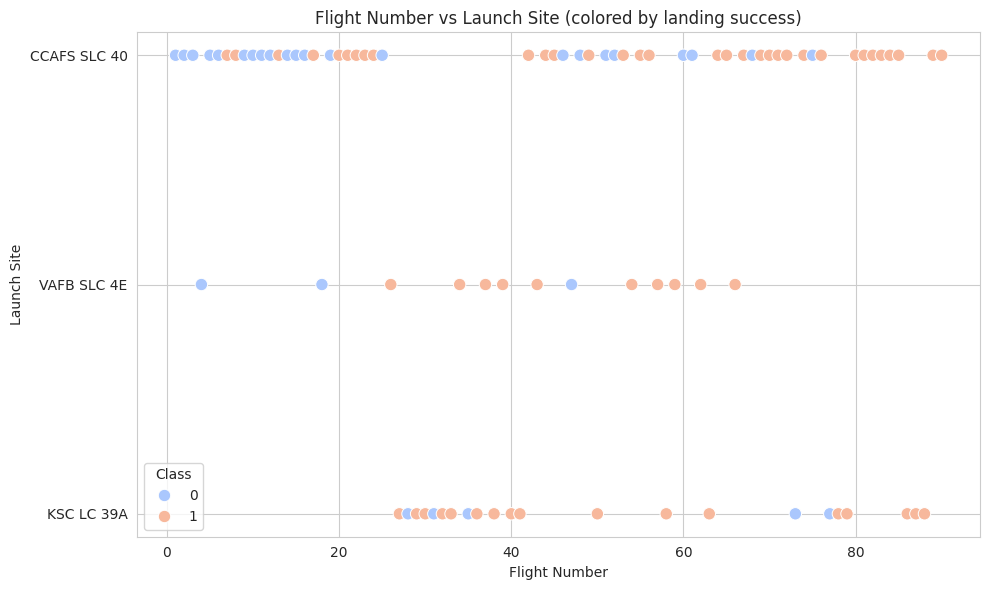

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='FlightNumber', y='LaunchSite', hue='Class', palette='coolwarm', s=80)
plt.title('Flight Number vs Launch Site (colored by landing success)')
plt.xlabel('Flight Number')
plt.ylabel('Launch Site')
plt.tight_layout()
plt.savefig('chart_flight_vs_site.png', dpi=100)
plt.show()

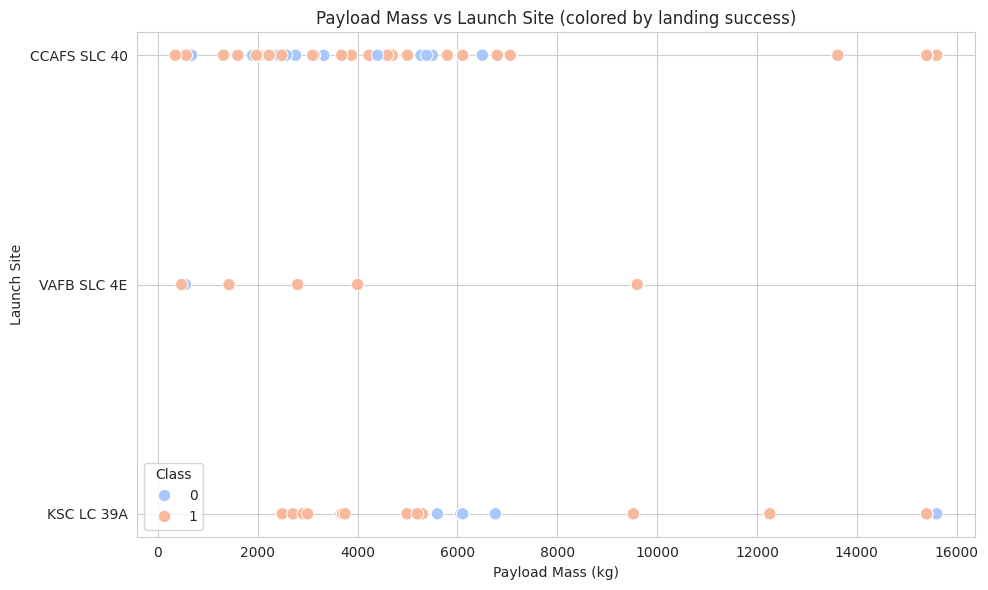

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='PayloadMass', y='LaunchSite', hue='Class', palette='coolwarm', s=80)
plt.title('Payload Mass vs Launch Site (colored by landing success)')
plt.xlabel('Payload Mass (kg)')
plt.ylabel('Launch Site')
plt.tight_layout()
plt.savefig('chart_payload_vs_site.png', dpi=100)
plt.show()

/tmp/ipykernel_645/1428259912.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=orbit_success, x='Orbit', y='SuccessRate', palette='viridis')


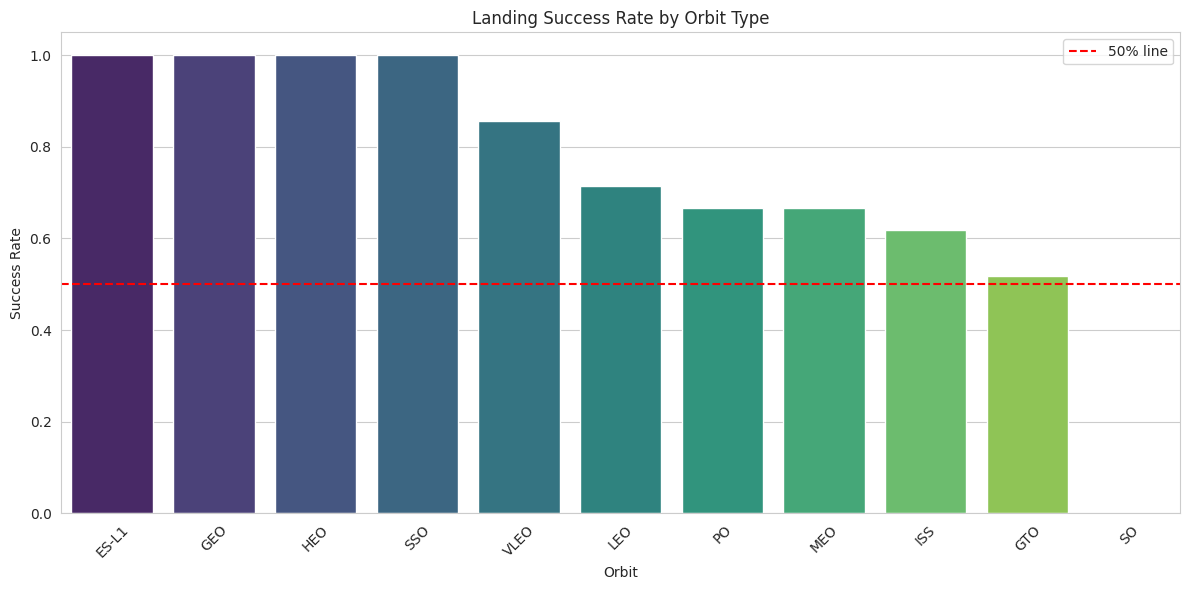

    Orbit  SuccessRate
0   ES-L1     1.000000
1     GEO     1.000000
3     HEO     1.000000
9     SSO     1.000000
10   VLEO     0.857143
5     LEO     0.714286
7      PO     0.666667
6     MEO     0.666667
4     ISS     0.619048
2     GTO     0.518519
8      SO     0.000000


In [16]:
# Success rate per Orbit
orbit_success = df.groupby('Orbit')['Class'].mean().reset_index()
orbit_success.columns = ['Orbit', 'SuccessRate']
orbit_success = orbit_success.sort_values('SuccessRate', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=orbit_success, x='Orbit', y='SuccessRate', palette='viridis')
plt.title('Landing Success Rate by Orbit Type')
plt.xlabel('Orbit')
plt.ylabel('Success Rate')
plt.xticks(rotation=45)
plt.axhline(y=0.5, color='red', linestyle='--', label='50% line')
plt.legend()
plt.tight_layout()
plt.savefig('chart_orbit_success.png', dpi=100)
plt.show()

print(orbit_success)

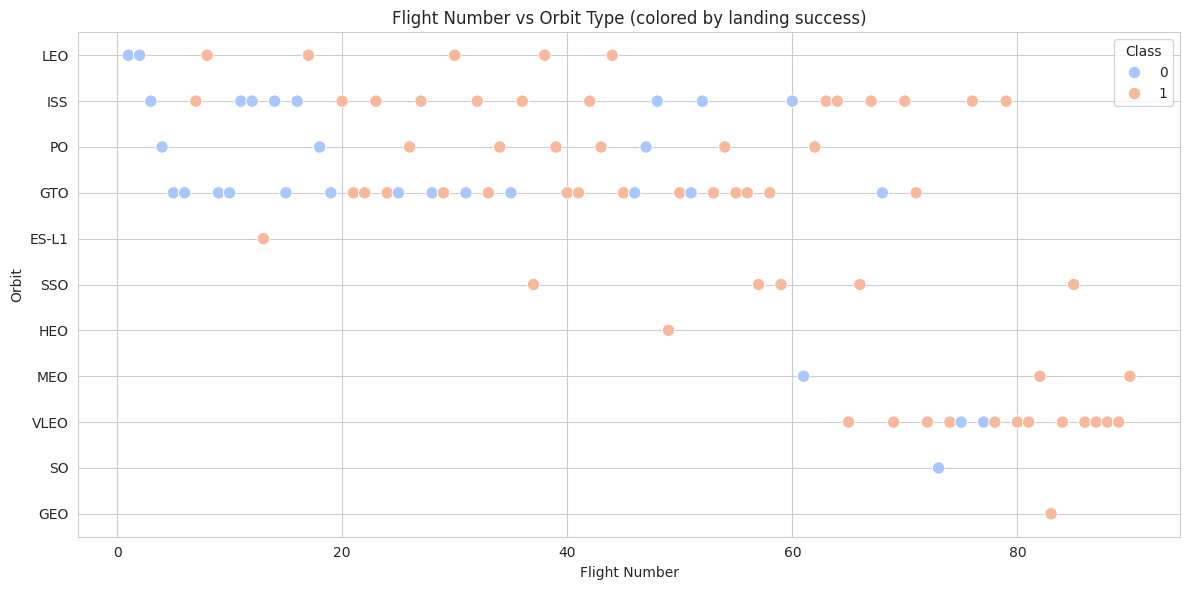

In [17]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='FlightNumber', y='Orbit', hue='Class', palette='coolwarm', s=80)
plt.title('Flight Number vs Orbit Type (colored by landing success)')
plt.xlabel('Flight Number')
plt.ylabel('Orbit')
plt.tight_layout()
plt.savefig('chart_flight_vs_orbit.png', dpi=100)
plt.show()

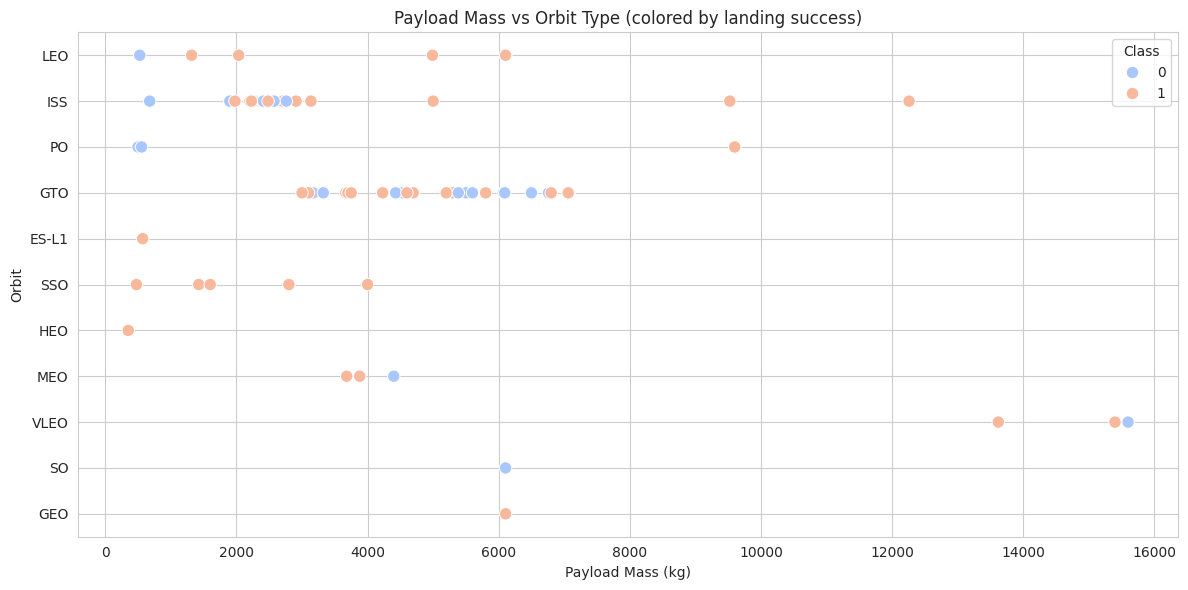

In [18]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='PayloadMass', y='Orbit', hue='Class', palette='coolwarm', s=80)
plt.title('Payload Mass vs Orbit Type (colored by landing success)')
plt.xlabel('Payload Mass (kg)')
plt.ylabel('Orbit')
plt.tight_layout()
plt.savefig('chart_payload_vs_orbit.png', dpi=100)
plt.show()

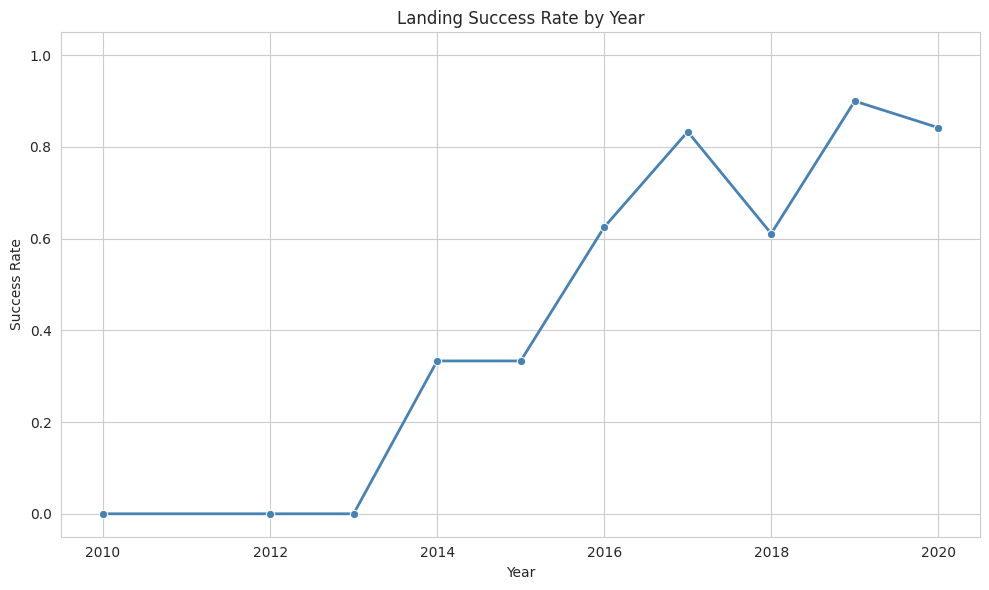

   Year  SuccessRate
0  2010     0.000000
1  2012     0.000000
2  2013     0.000000
3  2014     0.333333
4  2015     0.333333
5  2016     0.625000
6  2017     0.833333
7  2018     0.611111
8  2019     0.900000
9  2020     0.842105


In [19]:
# Extract year from Date
df['Year'] = pd.to_datetime(df['Date']).dt.year

# Success rate per year
yearly = df.groupby('Year')['Class'].mean().reset_index()
yearly.columns = ['Year', 'SuccessRate']

plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly, x='Year', y='SuccessRate', marker='o', linewidth=2, color='steelblue')
plt.title('Landing Success Rate by Year')
plt.xlabel('Year')
plt.ylabel('Success Rate')
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.tight_layout()
plt.savefig('chart_yearly_success.png', dpi=100)
plt.show()

print(yearly)

In [20]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(':memory:')
df.to_sql('SPACEXTABLE', conn, index=False, if_exists='replace')

# Q1 (revised): Total payload mass by Block (booster generation)
q1 = """
SELECT Block, SUM(PayloadMass) AS TotalPayloadMass, COUNT(*) AS NumLaunches
FROM SPACEXTABLE
GROUP BY Block
ORDER BY TotalPayloadMass DESC;
"""
print("--- Q1: Total Payload Mass by Booster Block ---")
print(pd.read_sql(q1, conn))

# Q2: Average payload mass by launch site
q2 = """
SELECT LaunchSite, AVG(PayloadMass) AS AvgPayloadMass
FROM SPACEXTABLE
GROUP BY LaunchSite
ORDER BY AvgPayloadMass DESC;
"""
print("\n--- Q2: Average Payload Mass by Launch Site ---")
print(pd.read_sql(q2, conn))

# Q3: Number of launches per launch site
q3 = """
SELECT LaunchSite, COUNT(*) AS NumLaunches
FROM SPACEXTABLE
GROUP BY LaunchSite
ORDER BY NumLaunches DESC;
"""
print("\n--- Q3: Number of Launches per Launch Site ---")
print(pd.read_sql(q3, conn))

--- Q1: Total Payload Mass by Booster Block ---
   Block  TotalPayloadMass  NumLaunches
0    5.0     343645.618824           39
1    3.0      79812.959412           15
2    4.0      53900.809412           11
3    1.0      48997.959412           19
4    2.0      23089.000000            6

--- Q2: Average Payload Mass by Launch Site ---
     LaunchSite  AvgPayloadMass
0    KSC LC 39A     7606.450856
1   VAFB SLC 4E     5919.461538
2  CCAFS SLC 40     5548.207786

--- Q3: Number of Launches per Launch Site ---
     LaunchSite  NumLaunches
0  CCAFS SLC 40           55
1    KSC LC 39A           22
2   VAFB SLC 4E           13


In [21]:
# Q4: Total payload mass by launch site
q4 = """
SELECT LaunchSite, SUM(PayloadMass) AS TotalPayloadMass
FROM SPACEXTABLE
GROUP BY LaunchSite
ORDER BY TotalPayloadMass DESC;
"""
print("--- Q4: Total Payload Mass by Launch Site ---")
print(pd.read_sql(q4, conn))

# Q5: Count of successful vs failed landings
q5 = """
SELECT Class, COUNT(*) AS Count
FROM SPACEXTABLE
GROUP BY Class;
"""
print("\n--- Q5: Successful (1) vs Failed (0) Landings ---")
print(pd.read_sql(q5, conn))

# Q6: Launch count per year
q6 = """
SELECT strftime('%Y', Date) AS Year, COUNT(*) AS NumLaunches
FROM SPACEXTABLE
GROUP BY Year
ORDER BY Year;
"""
print("\n--- Q6: Number of Launches per Year ---")
print(pd.read_sql(q6, conn))

# Q7: Max payload mass for each orbit
q7 = """
SELECT Orbit, MAX(PayloadMass) AS MaxPayloadMass
FROM SPACEXTABLE
GROUP BY Orbit
ORDER BY MaxPayloadMass DESC;
"""
print("\n--- Q7: Max Payload Mass by Orbit ---")
print(pd.read_sql(q7, conn))

--- Q4: Total Payload Mass by Launch Site ---
     LaunchSite  TotalPayloadMass
0  CCAFS SLC 40     305151.428235
1    KSC LC 39A     167341.918824
2   VAFB SLC 4E      76953.000000

--- Q5: Successful (1) vs Failed (0) Landings ---
   Class  Count
0      0     30
1      1     60

--- Q6: Number of Launches per Year ---
   Year  NumLaunches
0  2010            1
1  2012            1
2  2013            3
3  2014            6
4  2015            6
5  2016            8
6  2017           18
7  2018           18
8  2019           10
9  2020           19

--- Q7: Max Payload Mass by Orbit ---
    Orbit  MaxPayloadMass
0    VLEO    15600.000000
1     ISS    12259.000000
2      PO     9600.000000
3     GTO     7076.000000
4      SO     6104.959412
5     LEO     6104.959412
6     GEO     6104.959412
7     MEO     4400.000000
8     SSO     4000.000000
9   ES-L1      570.000000
10    HEO      350.000000


In [22]:
# Save the working dataset with the Year column added
df.to_csv('dataset_part_2_with_year.csv', index=False)
print("Saved. Shape:", df.shape)

Saved. Shape: (90, 19)


In [23]:
!pip install folium plotly dash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 72.9 MB/s eta 0:00:00


In [24]:
import folium
from IPython.display import display

site_coords = {
    'CCAFS SLC 40': [28.561857, -80.577366],
    'VAFB SLC 4E':  [34.632093, -120.610829],
    'KSC LC 39A':   [28.573305, -80.646895],
}
site_colors = {'CCAFS SLC 40': 'blue', 'VAFB SLC 4E': 'green', 'KSC LC 39A': 'red'}

# Use CartoDB Positron tiles (no block, clean look)
site_map = folium.Map(
    location=[29.5, -85],
    zoom_start=4,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Esri'
)

# Launch site markers
for site, coords in site_coords.items():
    folium.Marker(
        location=coords,
        popup=site,
        icon=folium.Icon(color=site_colors[site], icon='rocket', prefix='fa')
    ).add_to(site_map)

# Success markers
success_df = df[df['Class'] == 1]
for _, row in success_df.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=4,
        color='green',
        fill=True,
        fill_color='green',
        fill_opacity=0.6,
        popup=f"Flight {row['FlightNumber']} - Success"
    ).add_to(site_map)

site_map.save('spacex_launch_sites.html')
display(site_map)

In [25]:
import folium
from IPython.display import display

site_coords = {
    'CCAFS SLC 40': [28.561857, -80.577366],
    'VAFB SLC 4E':  [34.632093, -120.610829],
    'KSC LC 39A':   [28.573305, -80.646895],
}
site_colors = {'CCAFS SLC 40': 'blue', 'VAFB SLC 4E': 'green', 'KSC LC 39A': 'red'}

site_map = folium.Map(
    location=[30, -95],
    zoom_start=4,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Esri'
)

# Launch site markers (icons)
for site, coords in site_coords.items():
    folium.Marker(
        location=coords, popup=site,
        icon=folium.Icon(color=site_colors[site], icon='rocket', prefix='fa')
    ).add_to(site_map)

# Success circles (green)
for _, row in df[df['Class'] == 1].iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5, color='green', fill=True, fill_color='green', fill_opacity=0.6,
        popup=f"Flight {row['FlightNumber']} - Landing Success"
    ).add_to(site_map)

# Failure circles (red)
for _, row in df[df['Class'] == 0].iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5, color='red', fill=True, fill_color='red', fill_opacity=0.6,
        popup=f"Flight {row['FlightNumber']} - Landing Failure"
    ).add_to(site_map)

# Add a legend
legend_html = '''
<div style="position: fixed; bottom: 50px; left: 50px; z-index: 9999; background: white;
     padding: 10px; border: 2px solid grey; font-size: 14px;">
<b>Landing Outcome</b><br>
<i style="background:green; width:12px; height:12px; display:inline-block; border-radius:50%;"></i> Success<br>
<i style="background:red; width:12px; height:12px; display:inline-block; border-radius:50%;"></i> Failure
</div>
'''
site_map.get_root().html.add_child(folium.Element(legend_html))

site_map.save('spacex_launch_sites.html')
display(site_map)

In [26]:
!pip install jupyter-dash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 66.1 MB/s eta 0:00:00


In [27]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px
import pandas as pd

app = Dash(__name__)

app.layout = html.Div([
    html.H1("SpaceX Falcon 9 Landing Dashboard",
            style={'textAlign': 'center', 'color': '#503D36', 'fontSize': 30}),

    html.Div([
        html.H2("Landing Outcome Overview", style={'textAlign': 'center'}),
        dcc.Graph(
            id='success-pie-chart',
            figure=px.pie(
                df, names='Class',
                title='Landing Success vs Failure',
                color='Class',
                color_discrete_map={0: 'red', 1: 'green'}
            )
        )
    ]),

    html.Div([
        html.H2("Payload Mass vs Launch Outcome by Site", style={'textAlign': 'center'}),
        dcc.Dropdown(
            id='site-dropdown',
            options=[{'label': 'All Sites', 'value': 'ALL'}] +
                    [{'label': s, 'value': s} for s in df['LaunchSite'].unique()],
            value='ALL',
            placeholder='Select a Launch Site',
            searchable=True
        ),
        dcc.Graph(id='success-payload-scatter-chart')
    ])
])

@app.callback(
    Output('success-payload-scatter-chart', 'figure'),
    [Input('site-dropdown', 'value')]
)
def update_scatter(selected_site):
    if selected_site == 'ALL':
        filtered = df
        title = 'All Sites'
    else:
        filtered = df[df['LaunchSite'] == selected_site]
        title = selected_site

    fig = px.scatter(
        filtered, x='PayloadMass', y='Class',
        color='Class',
        title=f'Payload Mass vs Landing Outcome — {title}',
        labels={'Class': 'Landing Success (0=Fail, 1=Success)'}
    )
    return fig

# Modern Dash run method (no run_server, no jupyter_dash)
app.run(jupyter_mode='inline', port=8051)

<IPython.core.display.Javascript object>

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Select features
features = df[['Flights', 'GridFins', 'Reused', 'Legs', 'PayloadMass',
               'Orbit', 'LaunchSite', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]

# One-hot encode categoricals
X = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
y = df['Class'].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class balance:", np.bincount(y))

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
print("Train:", X_train.shape, "Test:", X_test.shape)

# Standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X shape: (90, 79)
y shape: (90,)
Class balance: [30 60]
Train: (72, 79) Test: (18, 79)


In [29]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# Define parameter grids
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=10000),
        'params': {'C': [0.01, 0.1, 1, 10], 'penalty': ['l2'], 'solver': ['lbfgs']}
    },
    'SVM': {
        'model': SVC(),
        'params': {'C': [0.5, 1, 10, 100], 'kernel': ['rbf', 'linear', 'poly', 'sigmoid'],
                   'gamma': ['scale', 'auto']}
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(),
        'params': {'criterion': ['gini', 'entropy'],
                   'max_depth': [2, 4, 6, 8, 10, 12],
                   'splitter': ['best', 'random']}
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
                   'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
                   'p': [1, 2]}
    }
}

results = {}
for name, config in param_grids.items():
    print(f"\nTraining {name}...")
    grid = GridSearchCV(config['model'], config['params'], cv=10, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train_scaled, y_train)

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results[name] = {
        'best_params': grid.best_params_,
        'test_accuracy': acc,
        'confusion_matrix': cm
    }
    print(f"  Best params: {grid.best_params_}")
    print(f"  Test accuracy: {acc:.4f}")
    print(f"  Confusion matrix:\n{cm}")

# Summary table
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
summary = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[m]['test_accuracy'] for m in results]
}).sort_values('Test Accuracy', ascending=False)
print(summary.to_string(index=False))

# Identify best model
best_name = summary.iloc[0]['Model']
print(f"\nBest model: {best_name}")


Training Logistic Regression...
  Best params: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
  Test accuracy: 0.8333
  Confusion matrix:
[[ 3  3]
 [ 0 12]]

Training SVM...
  Best params: {'C': 0.5, 'gamma': 'scale', 'kernel': 'sigmoid'}
  Test accuracy: 0.8333
  Confusion matrix:
[[ 3  3]
 [ 0 12]]

Training Decision Tree...
  Best params: {'criterion': 'gini', 'max_depth': 2, 'splitter': 'random'}
  Test accuracy: 0.7778
  Confusion matrix:
[[ 2  4]
 [ 0 12]]

Training KNN...
  Best params: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
  Test accuracy: 0.8333
  Confusion matrix:
[[ 3  3]
 [ 0 12]]

SUMMARY
              Model  Test Accuracy
Logistic Regression       0.833333
                SVM       0.833333
                KNN       0.833333
      Decision Tree       0.777778

Best model: Logistic Regression


/tmp/ipykernel_645/1223027853.py:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




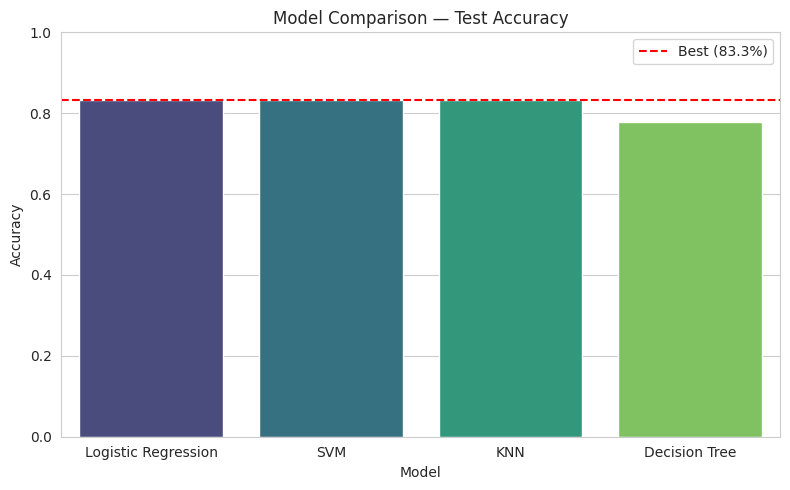

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Test Accuracy', data=summary, palette='viridis')
plt.title('Model Comparison — Test Accuracy')
plt.ylim(0, 1)
plt.axhline(y=0.8333, color='red', linestyle='--', label='Best (83.3%)')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.savefig('chart_model_comparison.png', dpi=100)
plt.show()